# Optics from BPM data of a RCS ring

BPM data reach EICViBE as a `TurnByTurn` acquisition, whoever recorded it: a file (HDF5, EICViBE's
own or plain matrices, `read_hdf5`; SDDS, `read_sdds`) or a virtual ring's run (ADR 0007). So one
analysis serves them all. This notebook kicks a virtual RCS whose quadrupoles have field errors,
writes what its BPMs read into an HDF5 file, and reads it back.
From the file and from the run it measures the tunes, the phase advances and the beta-beating, and
checks them against the model and against the truth: the optics with the errors the run hid.

With a measured file, everything below the file stays the same; its machine's model would take the
place of the RCS's.

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd

import eicvibe.notebook as ev
from eicvibe.domain.lattice import ElementKind
from eicvibe.virtual import MagnetErrors, Selection

MACHINE = Path(os.environ.get("EICVIBE_MACHINE", "../../virtual_accelerator/EIN/machine"))
RUNS = Path(os.environ.get("EICVIBE_RUNS", "runs"))
ENGINE = "trackpad" if ev.engine("trackpad").available() else "xsuite"

m = ev.machine(MACHINE)

## A ring with errors

Every quadrupole's gradient off by 0.3 % rms, and BPMs with 1 % gain errors and 0.1 mm offsets,
drawn from a seed: the same machine every time. The run hides them from its BPM data, as a real
machine does.

In [2]:
spec = ev.ErrorSpec(
    seed=5,
    magnets=[MagnetErrors(select=Selection(kinds=[ElementKind.QUADRUPOLE], branches=["rcs"]), field=3e-3)],
    bpms=ev.BpmModel(gain_rms=0.01, offset_rms=0.1),
)
errors = ev.MachineErrors(spec, m.lattice, ["rcs"], m.registry)
print(f"{len(errors.factors)} quadrupole gradients with errors")

192 quadrupole gradients with errors


The ring tracks at injection; a kick (a pinger's) starts a betatron oscillation, and the BPMs'
buffer around it is kept as a capture.

In [3]:
run = ev.start_ring(m, "rcs", RUNS / f"rcs-errors-{time.strftime('%Y%m%d-%H%M%S')}", errors=errors,
                   bpm=spec.bpm_model(), ramp=False, engine=ENGINE, beam=ev.Beam(particles=16), turns=3072)
run.wait(256)
run.kick(x=30e-6, y=30e-6)
run.wait(3072)
run.stop()
history = run.history
[kick] = [c for c in history.captures() if c["kind"] == "kick"]
captured = history.capture(kick["id"])
after = captured.window(kick["trigger"] - captured.first_turn, 1024)  # the 1024 turns after the kick
after

source,"virtual rcs run rcs-20261021T172932 (trackpad, standard), capture 000000000460-kick (kick)"
turns,"460 to 1,484 (1,024)"
BPMs,"192 x, 192 y; 100.0% of the x readings valid"
first turn at,2026-10-21 17:29:32
events,"5: capture, inject, kick, start"


## The same turns in a file

`write_hdf5` writes an acquisition as HDF5, EICViBE's default for BPM data: per plane the BPMs'
names, s, readings, sum signal and status, with the acquisition's ring, first turn, time and events;
`read_hdf5` reads it back whole. `write_sdds` and `read_sdds` do the same in the SDDS turn-by-turn
layout, for tools made for SDDS files.

In [4]:
path = RUNS / "rcs-kick.h5"
ev.write_hdf5(after, path)
acquisition = ev.read_hdf5(path)
print(f"{path}: {path.stat().st_size / 1e6:.1f} MB; largest difference from the run's readings "
      f"{np.nanmax(np.abs(acquisition.x.position - after.x.position)):.1g} mm")
acquisition

runs/rcs-kick.h5: 9.5 MB; largest difference from the run's readings 0 mm


source,"virtual rcs run rcs-20261021T172932 (trackpad, standard), capture 000000000460-kick (kick)"
turns,"460 to 1,484 (1,024)"
BPMs,"192 x, 192 y; 100.0% of the x readings valid"
first turn at,2026-10-21 17:29:32
events,"5: capture, inject, kick, start"


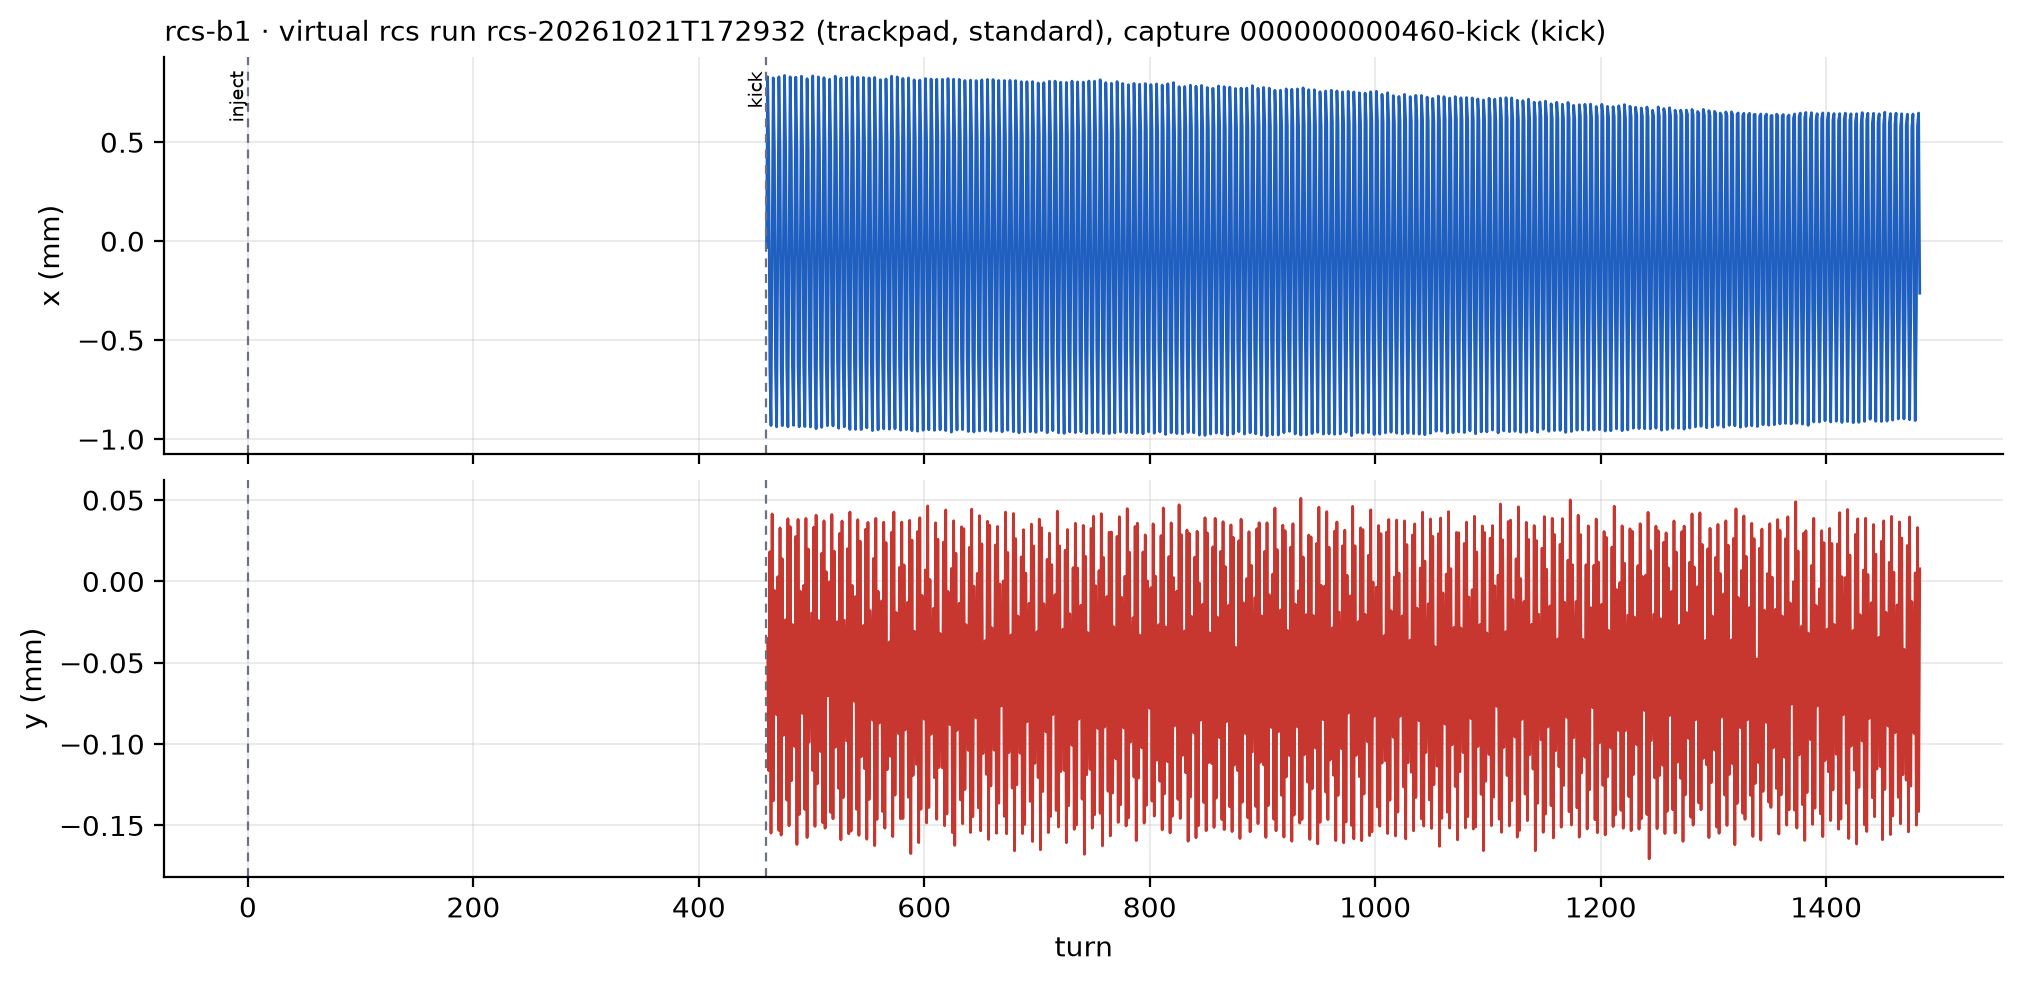

In [5]:
ev.plot_turns(acquisition, 0)

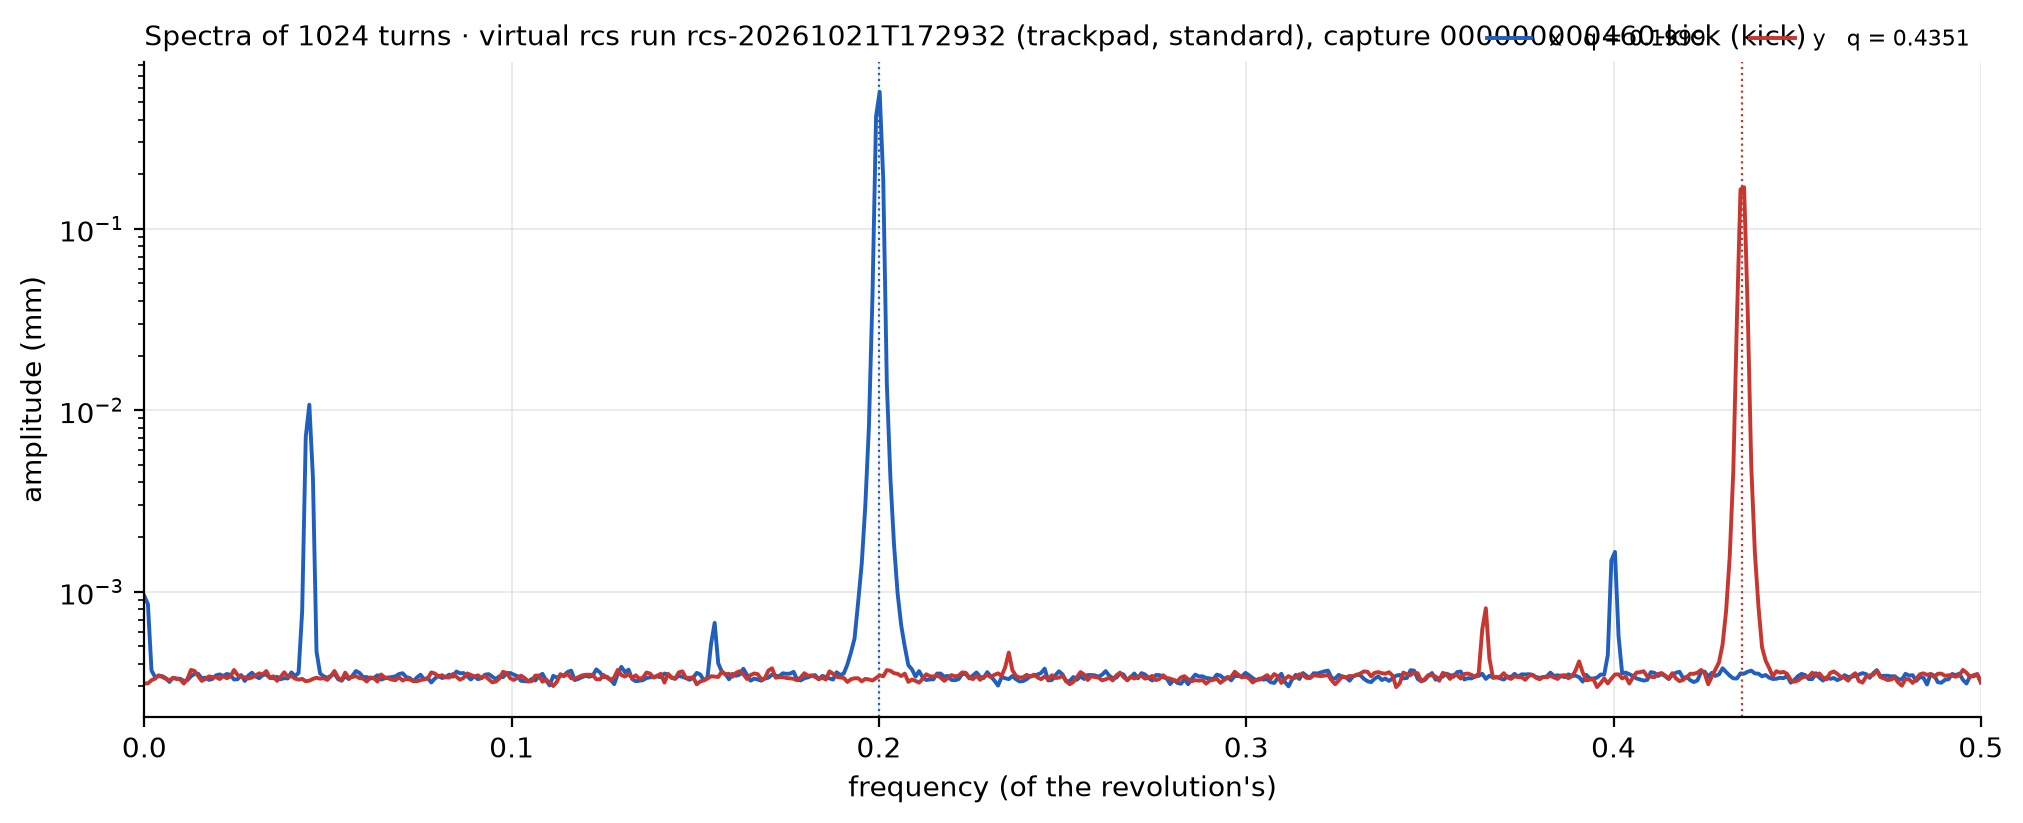

In [6]:
ev.plot_spectrum(acquisition)

## The analysis

For each plane: the tune (the strongest line, median over the BPMs), each BPM's line at that tune
(amplitude and phase), the phase advances against the model's, and the beta-beating from the
amplitudes: A² / β is the same everywhere for a free oscillation, so its spread about the median is
the beta-beating, with the BPMs' gain errors in it.

In [7]:
design = ev.optics(m, "rcs", engine=ENGINE)
truth = ev.optics(m, "rcs", engine=ENGINE, values=errors.engine_values({}, complete=True))
at = dict(zip(history.info.bpms, history.info.occurrences))  # BPM name -> the occurrence it reads at


def analyse(data: ev.TurnByTurn, plane: str) -> tuple[float, pd.DataFrame]:
    readings = data.plane(plane)
    q = ev.tune(data, plane)
    amplitude, phase = ev.harmonics(readings, q)
    index = [design.occurrences.index(at[b]) for b in readings.bpms]
    beta = np.array(getattr(design, f"beta_{plane}"))[index]
    mu = np.array(getattr(design, f"mu_{plane}"))[index]
    errors, _ = ev.phase_errors(phase, mu)
    return q, pd.DataFrame(
        {
            "s": readings.s,
            "amplitude (mm)": amplitude,
            "phase error (2π)": errors,
            "beta-beating": ev.beta_beating(amplitude, beta),
            "true beta-beating": np.array(getattr(truth, f"beta_{plane}"))[index] / beta - 1,
        },
        index=pd.Index(readings.bpms, name="bpm"),
    )


results = {(source, plane): analyse(data, plane) for source, data in (("file", acquisition), ("run", after)) for plane in "xy"}
pd.DataFrame(
    {
        "design": [design.tune_x % 1, design.tune_y % 1],
        "true": [truth.tune_x % 1, truth.tune_y % 1],
        "file": [results["file", p][0] for p in "xy"],
        "run": [results["run", p][0] for p in "xy"],
    },
    index=["q x", "q y"],
).round(5)

,design,true,file,run
q x,0.20020,0.19982,0.19992,0.19992
q y,0.43751,0.43502,0.43508,0.43508


The tunes the BPMs see are the true ones, not the design's: the errors moved them. The file and the
run agree to their last digit; from here on, the file's.

In [8]:
for plane in "xy":
    frame = results["file", plane][1]
    measured, true = frame["beta-beating"], frame["true beta-beating"]
    print(f"{plane}: beta-beating rms {measured.std():.3f} measured, {true.std():.3f} true; "
          f"their correlation {np.corrcoef(measured, true)[0, 1]:.2f}; phase errors rms {frame['phase error (2π)'].std():.4f}")

x: beta-beating rms 0.069 measured, 0.067 true; their correlation 0.96; phase errors rms 0.0070
y: beta-beating rms 0.063 measured, 0.063 true; their correlation 0.96; phase errors rms 0.0072


In [9]:
x = results["file", "x"][1]
ev.chart({"measured": (x.s, x["beta-beating"]), "true": (x.s, x["true beta-beating"])},
         title="Horizontal beta-beating at the BPMs", x_label="s (m)", y_label="Δβ/β", style="both", names=list(x.index))

In [10]:
y = results["file", "y"][1]
ev.chart({"measured": (y.s, y["beta-beating"]), "true": (y.s, y["true beta-beating"])},
         title="Vertical beta-beating at the BPMs", x_label="s (m)", y_label="Δβ/β", style="both", names=list(y.index))

In [11]:
ev.chart({"x": (x.s, x["phase error (2π)"]), "y": (y.s, y["phase error (2π)"])},
         title="Phase advance from the first BPM, against the design", x_label="s (m)", y_label="2π", style="both")

The measured beta-beating follows the true one; what is left is the BPMs' gain errors (1 % rms,
2 % in A²) and their noise. A measurement of the beta functions from the phases alone (three BPMs at a
time) would not see the gains.

## Next

- Read a measured file (`ev.read_sdds`, or `ev.read_hdf5` for HDF5 matrices): the analysis is the same.
- `eicvibe-virtual export RUN FILE` writes a run's turns as this notebook did (HDF5; SDDS for a `.sdds`
  file), from the command line.
- Correct the beta-beating: a response of the phases to the quadrupoles' strings, as the orbit's to
  the correctors (`eicvibe.operations`).